In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import sys
import os
# This gets the absolute path to the 'EE675' folder
parent_folder = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add it to the system path if it's not already there
if parent_folder not in sys.path:
    sys.path.append(parent_folder)

from kernel import kernel
from reward import reward
from value_iteration import value_iteration
from policy_iteration import policy_iteration

In [ ]:
%load_ext autoreload
%autoreload 2

In [7]:
def run_comparison():
    Ns = [2, 4, 6, 8, 10, 12]
    l1_differences = []
    times_vi = []
    times_pi = []
    
    gamma = 0.99
    epsilon = 1e-8

    for N in Ns:
        print(f"Analyzing N = {N}...")
        
        # 1. Setup Environment
        Kernel = kernel(N)
        reward_func = reward(N)
        
        # 2. Run Value Iteration
        start_vi = time.time()
        Q_vi = value_iteration(Kernel, reward_func, gamma, epsilon)
        V_vi = np.max(Q_vi, axis=1)
        times_vi.append(time.time() - start_vi)
        
        # 3. Run Policy Iteration
        start_pi = time.time()
        Q_pi = policy_iteration(Kernel, reward_func, gamma, epsilon)
        V_pi = np.max(Q_pi, axis=1)
        times_pi.append(time.time() - start_pi)
        
        # 4. Calculate L1 Difference
        # L1 = sum(|V_vi - V_pi|)
        l1_diff = np.sum(np.abs(V_vi - V_pi))
        l1_differences.append(l1_diff)
        
        print(f"Done. L1 Diff: {l1_diff:.2e}")

    return Ns, l1_differences, times_vi, times_pi


In [8]:
# Run Comparison for both algorithms
Ns, diffs, t_vi, t_pi = run_comparison()

Analyzing N = 2...
Done. L1 Diff: 4.85e-08
Analyzing N = 4...
Done. L1 Diff: 2.36e-06
Analyzing N = 6...
Done. L1 Diff: 9.14e-06
Analyzing N = 8...
Done. L1 Diff: 1.07e-05
Analyzing N = 10...
Done. L1 Diff: 8.16e-04
Analyzing N = 12...
Done. L1 Diff: 1.24e-02


In [9]:
def plot_comparison(Ns, diffs, t_vi, t_pi):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: L1 Difference (Accuracy)
    ax1.plot(Ns, diffs, marker='o', color='purple', linewidth=2)
    ax1.set_title('$L_1$ Difference between $V^*_{VI}$ and $V^*_{PI}$')
    ax1.set_xlabel('Grid Size (N)')
    ax1.set_ylabel('Total L1 Error')
    ax1.set_yscale('log') # Errors are often very small
    ax1.grid(True, alpha=0.3)

    # Plot 2: Run Times (Efficiency)
    ax2.plot(Ns, t_vi, label='Value Iteration', marker='o', color='blue')
    ax2.plot(Ns, t_pi, label='Policy Iteration', marker='s', color='red')
    ax2.set_title('Computational Time vs N')
    ax2.set_xlabel('Grid Size (N)')
    ax2.set_ylabel('Time (seconds)')
    ax2.set_yscale('log')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

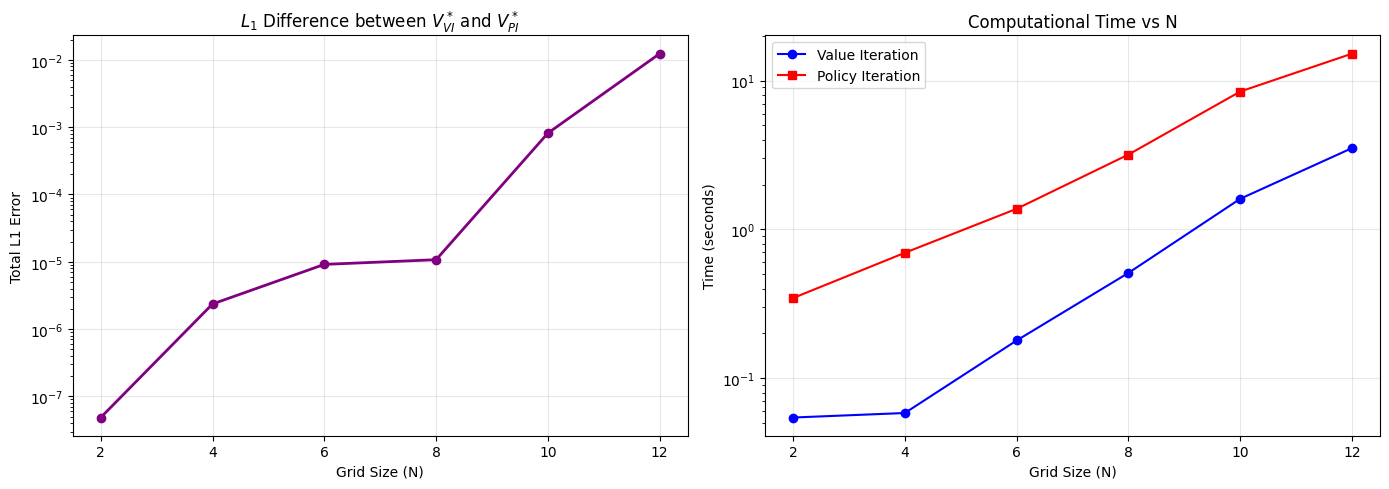

In [10]:
plot_comparison(Ns,diffs,t_vi,t_pi)